# 4.2 and 4.3 Interpretation and error analysis

Owner: Jingyu Wu

The first part rebuilds the section 3 pipeline and the section 4.1 candidate models, so this notebook runs on its own. Their reasoning and results are in `03_prepare_the_data.ipynb` and `04a_compare_models.ipynb`. The interpretation starts at **4.2 Model Interpretation and Feature Importance** below.

## 0. Setup

Starting from the team's final table (85,371 orders), the training period is orders purchased before 1 April 2018 (64,038 orders, split decided by the team, DECISIONS D6).

This notebook only uses the training data. The test set (orders from April 2018 onward) is not touched here and is evaluated at the end of the project.

The model inputs are the 22 approval-time features. IDs are excluded because they carry no meaning, raw dates are excluded because their information is already in the engineered timing features (plus the delivery date would be a data leakage), and is_late is of course excluded as this is the target variable

In [1]:
import pandas as pd
from pathlib import Path

# Find the project root
root = Path.cwd()

if not (root / "data").exists():
    root = root.parent

# Construct the CSV path
csv_path = root / "data" / "processed" / "olist_final.csv"

print("File exists:", csv_path.exists())

# Load dataset
df = pd.read_csv(
    csv_path,
    parse_dates=["order_purchase_timestamp"]
)

print("Dataset shape:", df.shape)
df = df.sort_values("order_purchase_timestamp").reset_index(drop=True)

# Training period only: orders purchased before 1 April 2018 (the team's split)
train = df[df["order_purchase_timestamp"] < "2018-04-01"]

# Features = everything except IDs, raw dates and the target
non_features = ["order_id", "customer_id", "order_purchase_timestamp", "order_approved_at",
                "order_delivered_customer_date", "order_estimated_delivery_date", "is_late"]
X_train = train.drop(columns=non_features)
y_train = train["is_late"]
print(X_train.shape)

File exists: True


Dataset shape: (85371, 29)
(64038, 22)


## Section 3 pipeline

Rebuilt here so this notebook runs on its own: the same 20 features and the same preprocessing as `03_prepare_the_data.ipynb`, where the reasoning behind each step is explained. Two columns are dropped (zip code and approval month), then imputation, the log transform, scaling and one-hot encoding are combined in one `ColumnTransformer` that is fitted on training data only.

In [7]:
print(X_train["customer_zip_code_prefix"].nunique())
print((X_train["approval_month"] == X_train["purchase_month"]).mean().round(3))

drop_cols = ["customer_zip_code_prefix", "approval_month"]
X_train_sel = X_train.drop(columns=drop_cols)
print(X_train_sel.shape)

13584
0.982
(64038, 20)


In [11]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer

dist_cols = ["mean_distance_km", "max_distance_km"]
weight_cols = ["mean_product_weight_g", "max_product_weight_g"]

# Skewed columns with no missing values: logged then scaled
log_cols = ["total_price", "seller_count", "total_freight", "item_count",
            "distinct_product_count", "total_product_volume_cm3",
            "approval_lag_hours", "freight_to_price_ratio", "promised_days_from_approval"]

# Skewed columns with missing values: filled, logged, then scaled
log_fill_cols = dist_cols + weight_cols

# Remaining numerical columns: only scaled
other_num = ["purchase_month", "purchase_weekday", "purchase_hour", "same_state_item_share"]

# Text columns
cat_cols = ["customer_state", "any_seller_state", "primary_product_category"]

# Logged then standardized
log_scale = Pipeline([("log", FunctionTransformer(np.log1p)),
                      ("scale", StandardScaler())])

# Medians filled, logged, then standardized
fill_log_scale = Pipeline([("fill", SimpleImputer(strategy="median")),
                           ("log", FunctionTransformer(np.log1p)),
                           ("scale", StandardScaler())])

# "unknown" filled, then one-hot (rare and unseen values become "infrequent")
cat_pipe = Pipeline([("fill", SimpleImputer(strategy="constant", fill_value="unknown")),
                     ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                              min_frequency=100))])

# Each step applied to its own columns
preprocess = ColumnTransformer([
    ("log_scale", log_scale, log_cols),
    ("fill_log_scale", fill_log_scale, log_fill_cols),
    ("dist_flag", MissingIndicator(features="all"), dist_cols),  # "was missing" flag
    ("scale", StandardScaler(), other_num),
    ("categories", cat_pipe, cat_cols),
], sparse_threshold=0)

# Check: fit on the training data only
X_pre = preprocess.fit_transform(X_train_sel)
print(X_pre.shape)
print(np.isnan(X_pre.astype(float)).sum())

(64038, 103)
0


Imports and the seven candidate models from section 4.1, with the same settings as `04a_compare_models.ipynb`. The benchmark itself is not repeated here; its results are in 04a.

In [12]:
import time
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

RANDOM_STATE = 42


The code below does three main things:
- Reuses the same preprocessing: Each model gets the existing preprocess transformations through a pipeline.
- Defines seven candidate algorithms: Logistic regression, balanced logistic regression, Linear SVM, Gaussian Naive Bayes, Decision Tree, Random Forest, and Histogram-based Gradient Boosting.
- Sets model parameters: Controls how each algorithm learns, including model complexity and training behavior.

In [14]:
def with_pre(clf):
    # Apply the same preprocessing to every model for a fair comparison.
    return Pipeline([("pre", clone(preprocess)), ("clf", clf)])


candidates = {
    # Provides a simple, interpretable baseline for predicting late orders.
    "Logistic Regression": with_pre(LogisticRegression(
        C=1.0, max_iter=2000, random_state=RANDOM_STATE)),

    # Late orders are only ~7% of the data, so this model gives more weight
    # to late orders to test whether it improves detection of the minority class.
    "Logistic Regression (balanced)": with_pre(LogisticRegression(
        C=1.0, max_iter=2000, class_weight="balanced",
        random_state=RANDOM_STATE)),

    # Tests a different linear decision boundary to see whether it ranks
    # late orders better than logistic regression.
    "Linear SVM": with_pre(LinearSVC(
        C=0.1, max_iter=5000, random_state=RANDOM_STATE)),

    # Provides a fast, probability-based model with different assumptions,
    # allowing us to test whether a simple statistical approach works well.
    "Gaussian Naive Bayes": with_pre(GaussianNB()),

    # Captures nonlinear relationships and feature interactions using rules.
    # Depth and leaf-size limits help reduce overfitting.
    "Decision Tree": with_pre(DecisionTreeClassifier(
        max_depth=6, min_samples_leaf=100, random_state=RANDOM_STATE)),

    # Combines many decision trees to capture complex patterns while
    # reducing the instability and overfitting of a single tree.
    "Random Forest": with_pre(RandomForestClassifier(
        n_estimators=300, min_samples_leaf=20, max_features="sqrt",
        n_jobs=-1, random_state=RANDOM_STATE)),

    # Builds trees sequentially, with each new tree correcting earlier errors.
    # Tests whether boosting can identify complex patterns missed by other models.
    "Gradient Boosting (HistGB)": with_pre(HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=300, max_leaf_nodes=31, min_samples_leaf=50,
        early_stopping=False, random_state=RANDOM_STATE)),
}

## 4.2 Model Interpretation and Feature Importance

### 4.2.1 Objective

This section examines which approval-time features are most influential in predicting late deliveries.

We first interpret a logistic regression model and then examine model errors using time-based validation data.

The held-out test set is not used during development.

In [18]:
import pandas as pd
from pathlib import Path

# Locate the project root
root = Path.cwd()

if not (root / "data").exists():
    root = root.parent

# Load the dataset
csv_path = root / "data" / "processed" / "olist_final.csv"

df = pd.read_csv(
    csv_path,
    parse_dates=["order_purchase_timestamp"]
)

print("CSV found:", csv_path.is_file())
print("Dataset shape:", df.shape)

CSV found: True
Dataset shape: (85371, 29)


In [19]:
from sklearn.base import clone

# Reuse the team's existing Logistic Regression pipeline
lr_model = clone(candidates["Logistic Regression"])

# Train on the training period only
lr_model.fit(X_train_sel, y_train)

print("Logistic Regression fitted successfully!")

Logistic Regression fitted successfully!


In [20]:
# Inspect the fitted pipeline
print(lr_model.named_steps.keys())

dict_keys(['pre', 'clf'])


In [21]:
import numpy as np
import pandas as pd

# Extract the fitted classifier
classifier = lr_model.named_steps["clf"]

# Numerical feature names
numeric_features = (
    log_cols
    + log_fill_cols
    + [f"{col}_missing" for col in dist_cols]
    + other_num
)

# Categorical feature names after One-Hot Encoding
onehot = (
    lr_model.named_steps["pre"]
    .named_transformers_["categories"]
    .named_steps["onehot"]
)

categorical_features = onehot.get_feature_names_out(cat_cols).tolist()

# Combine feature names in ColumnTransformer output order
feature_names = numeric_features + categorical_features

# Extract coefficients
coefficients = classifier.coef_[0]

print("Number of features:", len(feature_names))
print("Number of coefficients:", len(coefficients))

assert len(feature_names) == len(coefficients)

print("Feature names and coefficients aligned successfully!")

Number of features: 103
Number of coefficients: 103
Feature names and coefficients aligned successfully!


### 4.2.2 Logistic Regression Coefficient Analysis

**Results and Interpretation**

The figure presents the 15 largest absolute coefficients from the fitted Logistic Regression model.

Several observations can be made:

Customer Location: Geographic features show relatively large coefficients. For example, `customer_state_AL` (0.899) and `customer_state_RJ` (0.577) are positively associated with predicted late-delivery log-odds, while `customer_state_PR` (-0.727) and `customer_state_MG` (-0.684) show negative associations, conditional on other model inputs.

Product Categories: Product categories also exhibit different coefficient directions. For example, `primary_product_category_audio` (0.806) has a positive coefficient, while `primary_product_category_home_appliances` (-0.803) has a negative coefficient.

Promised Delivery Window: `promised_days_from_approval` (-0.712) has a negative coefficient, suggesting that longer promised delivery windows are associated with lower predicted late-delivery risk. This is consistent with the intuition that longer delivery windows provide more time to fulfill an order.

**Limitations**

These coefficients describe associations learned by the model rather than causal effects. Their magnitudes are influenced by preprocessing, feature scaling, categorical reference groups, and correlations between predictors. Therefore, the ranking should not be interpreted as a definitive measure of feature importance.

To complement this analysis, we will use Permutation Importance to evaluate how much predictive performance deteriorates when individual features are shuffled on time-based validation data.

In [22]:
# Create a coefficient table
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Calculate absolute coefficient values
coef_df["Abs_Coefficient"] = coef_df["Coefficient"].abs()

# Sort by absolute coefficient
coef_df = coef_df.sort_values(
    "Abs_Coefficient",
    ascending=False
)

# Display the top 15 features
display(coef_df.head(15))

,Feature,Coefficient,Abs_Coefficient
19,customer_state_AL,0.899076,0.899076
59,primary_product_category_audio,0.805825,0.805825
82,primary_product_category_home_appliances,-0.802742,0.802742
89,primary_product_category_luggage_accessories,-0.747102,0.747102
50,any_seller_state_PE,-0.733024,0.733024
34,customer_state_PR,-0.727281,0.727281
8,promised_days_from_approval,-0.711664,0.711664
27,customer_state_MG,-0.683953,0.683953
37,customer_state_RO,-0.667433,0.667433
53,any_seller_state_RS,-0.654246,0.654246


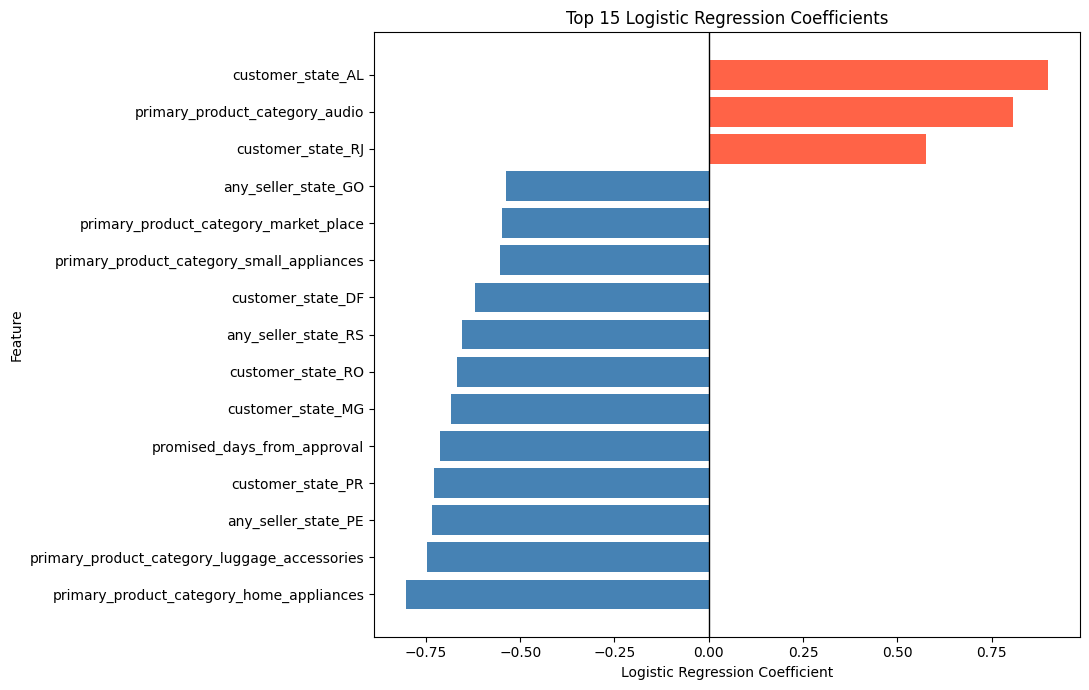

In [23]:
import matplotlib.pyplot as plt
import numpy as np

top15 = coef_df.head(15).sort_values("Coefficient")

plt.figure(figsize=(11, 7))

colors = np.where(
    top15["Coefficient"] > 0,
    "tomato",
    "steelblue"
)

plt.barh(
    top15["Feature"],
    top15["Coefficient"],
    color=colors
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Top 15 Logistic Regression Coefficients")

plt.tight_layout()
plt.show()

### 4.2.3 Permutation Feature Importance

While logistic regression coefficients indicate the direction and magnitude of associations in the fitted model, they do not directly measure each feature's contribution to predictive performance.

To provide a complementary perspective, permutation importance evaluates the decrease in PR-AUC after randomly shuffling one feature while keeping the others unchanged.

We use time-based validation data drawn exclusively from the training period. The model is fitted on earlier observations and evaluated on later observations, avoiding in-sample importance estimates and preserving the held-out test set for final evaluation.

In [24]:
import sys
from pathlib import Path

root = Path.cwd().resolve()
if not (root / "src").exists():
    root = root.parent

sys.path.insert(0, str(root))
from sklearn.base import clone
from src.evaluation import cv_splitter

# Use the team's existing time-series cross-validation strategy
cv = cv_splitter()

# Select the last training/validation split
train_idx, val_idx = list(cv.split(X_train_sel, y_train))[-1]

# Create chronological training and validation subsets
X_fit = X_train_sel.iloc[train_idx]
X_val = X_train_sel.iloc[val_idx]

y_fit = y_train.iloc[train_idx]
y_val = y_train.iloc[val_idx]

# Fit a fresh logistic regression pipeline
lr_val_model = clone(candidates["Logistic Regression"])
lr_val_model.fit(X_fit, y_fit)

print("Training observations:", len(X_fit))
print("Validation observations:", len(X_val))
print("Validation late rate:", round(y_val.mean(), 4))

Training observations: 51365
Validation observations: 10673
Validation late rate: 0.1884


In [25]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score

# Baseline performance on validation data
y_score = lr_val_model.predict_proba(X_val)[:, 1]

baseline_ap = average_precision_score(y_val, y_score)

print(f"Validation PR-AUC: {baseline_ap:.4f}")

# Permutation importance
perm_result = permutation_importance(
    lr_val_model,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Organize results
perm_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
}).sort_values("Importance", ascending=False)

display(perm_df.head(15))

Validation PR-AUC: 0.3559


,Feature,Importance,Std
5,customer_state,0.110839,0.004100
0,promised_days_from_approval,0.049606,0.004882
16,same_state_item_share,0.035093,0.001621
14,mean_distance_km,0.020651,0.001399
17,any_seller_state,0.016774,0.001197
18,primary_product_category,0.009041,0.002529
6,item_count,0.008920,0.001130
12,max_product_weight_g,0.006736,0.000786
9,total_price,0.005101,0.002524
19,freight_to_price_ratio,0.003479,0.001119


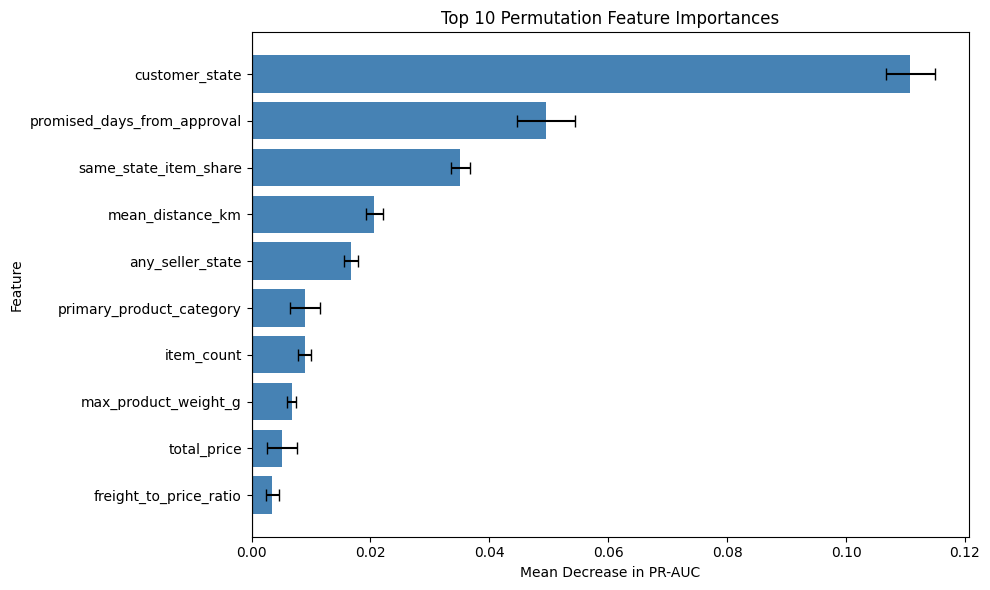

In [26]:
import matplotlib.pyplot as plt

top10 = perm_df.head(10).sort_values("Importance")

plt.figure(figsize=(10, 6))

plt.barh(
    top10["Feature"],
    top10["Importance"],
    xerr=top10["Std"],
    color="steelblue",
    capsize=4
)

plt.axvline(0, color="black", linewidth=0.8)

plt.xlabel("Mean Decrease in PR-AUC")
plt.ylabel("Feature")
plt.title("Top 10 Permutation Feature Importances")

plt.tight_layout()
plt.show()

**Results and Interpretation**

The logistic regression model achieved a validation PR-AUC of 0.3559 on the final time-based validation fold, compared with a late-delivery prevalence of 18.84%.

Permutation importance identifies `customer_state` as the most influential feature, with an average PR-AUC decrease of 0.1108 when shuffled. This is followed by `promised_days_from_approval` (0.0496), `same_state_item_share` (0.0351), and `mean_distance_km` (0.0207).

These findings suggest that geographic information, promised delivery windows, and shipping-related characteristics play important roles in the model's predictions.

Unlike coefficient magnitudes, permutation importance evaluates how much predictive performance depends on each original feature, making it particularly useful when categorical variables are expanded through one-hot encoding.

## 4.3 Error Analysis

### 4.3.1 Confusion Matrix and Top-10% Risk Identification

This section examines the types of prediction errors made by the logistic regression model on time-based validation data.

Following the project's operational objective, we identify the highest-risk 10% of orders based on predicted late-delivery probabilities.

We then construct a confusion matrix to evaluate how many late orders are successfully identified and how many are missed.

All analysis is conducted on the training-period validation fold without accessing the held-out test set.

In [27]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, precision_score, recall_score

# Step 1: Generate predicted late-delivery probabilities
y_prob = lr_val_model.predict_proba(X_val)[:, 1]

# Step 2: Select the highest-risk 10% of orders
n_top = int(np.ceil(len(y_prob) * 0.10))

top_indices = np.argsort(-y_prob, kind="stable")[:n_top]

# Step 3: Create binary predictions
y_pred_top10 = np.zeros(len(y_prob), dtype=int)
y_pred_top10[top_indices] = 1

# Step 4: Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_val,
    y_pred_top10,
    labels=[0, 1]
).ravel()

# Step 5: Calculate operational metrics
precision = precision_score(y_val, y_pred_top10, zero_division=0)
recall = recall_score(y_val, y_pred_top10, zero_division=0)

print(f"Validation orders: {len(y_val)}")
print(f"Flagged orders (Top 10%): {n_top}")
print(f"True Positives: {tp}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Negatives: {tn}")
print(f"Precision at Top 10%: {precision:.4f}")
print(f"Recall at Top 10%: {recall:.4f}")

Validation orders: 10673
Flagged orders (Top 10%): 1068
True Positives: 476
False Positives: 592
False Negatives: 1535
True Negatives: 8070
Precision at Top 10%: 0.4457
Recall at Top 10%: 0.2367


**Results and Interpretation**

On the selected time-based validation fold, the logistic regression model flagged the 10% highest-risk orders (1,068 out of 10,673 orders).

Among these flagged orders, 476 were actual late deliveries (true positives), while 592 arrived on time (false positives). The model missed 1,535 late orders (false negatives).

The resulting precision at the top 10% was 44.57%, and recall at the top 10% was 23.67%.

Compared with the validation late-delivery prevalence of 18.84%, the flagged orders had approximately 2.37 times the average late-delivery rate.

These findings suggest that the model provides useful risk prioritization. However, approximately 76.3% of late deliveries remain outside the highest-risk 10%, indicating an important limitation under the assumed operational review capacity.

These results apply to one time-based validation fold, not the held-out test set.

### 4.3.2 False Negative Analysis

False negatives are orders that were actually delivered late but were not included in the top 10% highest-risk predictions.

To investigate why these orders were missed, we compare their characteristics with true positives, which are late orders successfully identified by the model.

The analysis focuses on promised delivery windows, shipping distances, same-state shipping share, and order-level numerical characteristics.

In [28]:
# Build the error analysis dataset
error_df = X_val.copy().reset_index(drop=True)

error_df["actual"] = y_val.to_numpy()
error_df["predicted"] = y_pred_top10
error_df["predicted_risk"] = y_prob

conditions = [
    (error_df["actual"] == 1) & (error_df["predicted"] == 1),
    (error_df["actual"] == 1) & (error_df["predicted"] == 0),
    (error_df["actual"] == 0) & (error_df["predicted"] == 1),
    (error_df["actual"] == 0) & (error_df["predicted"] == 0)
]

error_df["error_type"] = np.select(
    conditions,
    ["TP", "FN", "FP", "TN"],
    default="Unknown"
)

print(error_df["error_type"].value_counts())

error_type
TN    8070
FN    1535
FP     592
TP     476
Name: count, dtype: int64


In [29]:
# Compare average characteristics of FN and TP orders
features = {
    "promised_days_from_approval": "Promised Days",
    "mean_distance_km": "Mean Distance (km)",
    "same_state_item_share": "Same-State Share",
    "item_count": "Item Count",
    "total_price": "Total Price",
    "total_freight": "Total Freight"
}

comparison = (
    error_df[error_df["error_type"].isin(["FN", "TP"])]
    .groupby("error_type")[list(features)]
    .mean()
    .T
    .rename(index=features)
    .rename(columns={"FN": "FN Mean", "TP": "TP Mean"})
    .round(2)
)

comparison["Finding"] = [
    "FN has slightly longer delivery windows",
    "TP orders travel farther",
    "TP orders are more concentrated in cross-state shipping",
    "Minimal difference",
    "TP orders have higher values",
    "TP orders have higher freight costs"
]

display(comparison.reset_index().rename(columns={"index": "Feature"}))

error_type,Feature,FN Mean,TP Mean,Finding
0,Promised Days,22.64,21.96,FN has slightly longer delivery windows
1,Mean Distance (km),727.11,1011.11,TP orders travel farther
2,Same-State Share,0.21,0.00,TP orders are more concentrated in cross-state...
3,Item Count,1.11,1.08,Minimal difference
4,Total Price,125.34,182.64,TP orders have higher values
5,Total Freight,23.10,35.01,TP orders have higher freight costs


**Results and Interpretation**

The comparison between true positives  and false negatives reveals several differences in the characteristics of late deliveries identified and missed by the logistic regression model.

Shipping Distance: Successfully identified late orders have a higher average shipping distance (1,011.11 km) than missed late orders (727.11 km). This suggests that the model may be more effective at recognizing late deliveries associated with longer shipping routes.

Geographic Characteristics: The average same-state item share is approximately 0.00 for TP orders, compared with 0.21 for FN orders. This indicates that missed late deliveries include a greater proportion of within-state shipments, while correctly identified late deliveries are more concentrated among cross-state shipments.

Order Value and Freight: TP orders have higher average order values (182.64 vs. 125.34) and freight costs (35.01 vs. 23.10). The model may be more likely to assign higher risk scores to orders with these characteristics.

Promised Delivery Window: FN orders have slightly longer average promised delivery windows (22.64 days) than TP orders (21.96 days), although this difference is relatively small.

### 4.3.3 False Positive Analysis

False positives are orders that were flagged among the top 10% highest-risk predictions but were actually delivered on time.

To understand these incorrect alerts, we compare false positives (FP) with true negatives (TN). Both groups were delivered on time, but only FP orders were flagged as high-risk.

The objective is to identify characteristics associated with unnecessary risk alerts and assess potential operational inefficiencies.

In [30]:
# Compare FP and TN characteristics
fp_tn = (
    error_df[error_df["error_type"].isin(["FP", "TN"])]
    .groupby("error_type")[list(features)]
    .mean()
    .T
    .rename(index=features)
    .rename(columns={"FP": "FP Mean", "TN": "TN Mean"})
    .round(2)
)

# Display a clean comparison table
fp_tn = fp_tn.reset_index().rename(
    columns={"index": "Feature"}
)

display(fp_tn)

error_type,Feature,FP Mean,TN Mean
0,Promised Days,23.05,21.69
1,Mean Distance (km),1172.41,518.63
2,Same-State Share,0.06,0.42
3,Item Count,1.15,1.16
4,Total Price,230.46,124.25
5,Total Freight,39.60,21.16


**Results and Interpretation**

The comparison between false positives (FP) and true negatives (TN) reveals clear differences in shipping-related characteristics, even though both groups were ultimately delivered on time.

Shipping Distance: FP orders have a substantially higher average shipping distance (1,172.41 km) than TN orders (518.63 km). This suggests that the model tends to assign higher risk scores to long-distance shipments, including those that arrive on time.

Geographic Characteristics: The average same-state item share is much lower for FP orders (0.06) than for TN orders (0.42), indicating a greater concentration of cross-state shipments among false positives.

Order Value and Freight: FP orders have higher average order values (230.46 vs. 124.25) and freight costs (39.60 vs. 21.16). These characteristics may be associated with the model's higher risk predictions.

Promised Delivery Window: FP orders have slightly longer promised delivery windows (23.05 days) than TN orders (21.69 days), while item counts are nearly identical.

### 4.3.4 Cross-Model Error Comparison

We compare three shortlisted models—Logistic Regression, Random Forest, and Gradient Boosting (HistGB)—using the same chronological training and validation split.

Each model identifies the highest-risk 10% of orders. We compare PR-AUC, Precision@10%, and Recall@10%, followed by an analysis of overlapping and model-specific prediction errors.

The held-out test set is not used.

In [31]:
# Fit HistGB on the same training fold
hgb_val_model = clone(candidates["Gradient Boosting (HistGB)"])
hgb_val_model.fit(X_fit, y_fit)

# Predict validation risk
hgb_prob = hgb_val_model.predict_proba(X_val)[:, 1]

# Select the highest-risk 10%
hgb_top_idx = np.argsort(-hgb_prob, kind="stable")[:n_top]

hgb_pred_top10 = np.zeros(len(hgb_prob), dtype=int)
hgb_pred_top10[hgb_top_idx] = 1

print("HistGB fitted and predictions generated.")

HistGB fitted and predictions generated.


In [32]:
from sklearn.base import clone
from sklearn.metrics import average_precision_score, precision_score, recall_score

# Train Random Forest on the same training fold
rf_val_model = clone(candidates["Random Forest"])
rf_val_model.fit(X_fit, y_fit)

# Predict late-delivery risk
rf_prob = rf_val_model.predict_proba(X_val)[:, 1]

# Flag the highest-risk 10% of orders
rf_top_idx = np.argsort(-rf_prob, kind="stable")[:n_top]

rf_pred_top10 = np.zeros(len(rf_prob), dtype=int)
rf_pred_top10[rf_top_idx] = 1

# Compare model performance
comparison_models = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting (HistGB)"
    ],
    "PR-AUC": [
        average_precision_score(y_val, y_prob),
        average_precision_score(y_val, rf_prob),
        average_precision_score(y_val, hgb_prob)
    ],
    "Precision@10%": [
        precision_score(y_val, y_pred_top10),
        precision_score(y_val, rf_pred_top10),
        precision_score(y_val, hgb_pred_top10)
    ],
    "Recall@10%": [
        recall_score(y_val, y_pred_top10),
        recall_score(y_val, rf_pred_top10),
        recall_score(y_val, hgb_pred_top10)
    ]
})

display(comparison_models.round(4))

,Model,PR-AUC,Precision@10%,Recall@10%
0,Logistic Regression,0.3559,0.4457,0.2367
1,Random Forest,0.3114,0.3755,0.1994
2,Gradient Boosting (HistGB),0.3044,0.3577,0.1900


In [33]:
actual_late = y_val.to_numpy() == 1

lr_detected = actual_late & (y_pred_top10 == 1)
rf_detected = actual_late & (rf_pred_top10 == 1)
hgb_detected = actual_late & (hgb_pred_top10 == 1)

overlap_summary = pd.DataFrame({
    "Category": [
        "Missed by all three models",
        "Detected by all three models",
        "Detected by at least one model",
        "Detected only by Logistic Regression",
        "Detected only by Random Forest",
        "Detected only by HistGB"
    ],
    "Orders": [
        np.sum(actual_late & ~lr_detected & ~rf_detected & ~hgb_detected),
        np.sum(lr_detected & rf_detected & hgb_detected),
        np.sum(lr_detected | rf_detected | hgb_detected),
        np.sum(lr_detected & ~rf_detected & ~hgb_detected),
        np.sum(rf_detected & ~lr_detected & ~hgb_detected),
        np.sum(hgb_detected & ~lr_detected & ~rf_detected)
    ]
})

display(overlap_summary)

,Category,Orders
0,Missed by all three models,1331
1,Detected by all three models,194
2,Detected by at least one model,680
3,Detected only by Logistic Regression,163
4,Detected only by Random Forest,60
5,Detected only by HistGB,72


**Results and Interpretation**

On the selected time-based validation fold, Logistic Regression achieved the highest PR-AUC (0.3559), Precision@10% (0.4457), and Recall@10% (0.2367), followed by Random Forest and HistGB.

The error overlap analysis shows that all three models missed 1,331 of the 2,011 actual late deliveries (66.2%), suggesting substantial shared prediction limitations.

However, the models also demonstrate complementary behavior. Logistic Regression uniquely detected 163 late orders, Random Forest uniquely detected 60, and HistGB uniquely detected 72. In total, at least one of the three models identified 680 late orders (33.8%).

Although Logistic Regression performed best individually on this validation fold, Random Forest and HistGB identified some late deliveries that Logistic Regression missed. This suggests potential benefits from combining different model families.

However, the combined coverage of 33.8% does not represent the performance of an operational ensemble under the top-10% review constraint. Any ensemble would need to be evaluated using a single risk ranking and the same review capacity.

### 4.3.5 Do the three models rely on the same variables?

Section 4.2 measured which variables matter for logistic regression only. The checklist asks for the most significant variables of each algorithm, so the same permutation test (drop in PR-AUC when one original column is shuffled, 5 repeats) is applied to the random forest and HistGB fitted on the same training fold and scored on the same validation fold.

In [34]:
from sklearn.inspection import permutation_importance

# Same test as 4.2.3, on the same fold, so the three models are compared like for like.
tree_importance = {}
for name, model in [("Random Forest", rf_val_model), ("Gradient Boosting (HistGB)", hgb_val_model)]:
    result = permutation_importance(model, X_val, y_val, scoring="average_precision",
                                    n_repeats=5, random_state=42, n_jobs=-1)
    tree_importance[name] = pd.Series(result.importances_mean, index=X_val.columns)

importance_compare = pd.DataFrame({
    "Logistic Regression": perm_df.set_index("Feature")["Importance"],
    **tree_importance,
})
# Rank by each column's largest importance in any model, so a variable that only one model relies on still shows up.
importance_compare = importance_compare.loc[importance_compare.max(axis=1).sort_values(ascending=False).index]

display(importance_compare.round(4))

,Logistic Regression,Random Forest,Gradient Boosting (HistGB)
customer_state,0.1108,0.0618,0.0470
promised_days_from_approval,0.0496,0.0187,0.0338
same_state_item_share,0.0351,0.0113,0.0369
mean_distance_km,0.0207,0.0054,0.0116
any_seller_state,0.0168,0.0058,0.0020
max_distance_km,0.0027,0.0019,0.0163
total_freight,0.0024,0.0046,0.0128
primary_product_category,0.0090,0.0002,0.0024
item_count,0.0089,0.0009,0.0015
max_product_weight_g,0.0067,-0.0009,0.0003


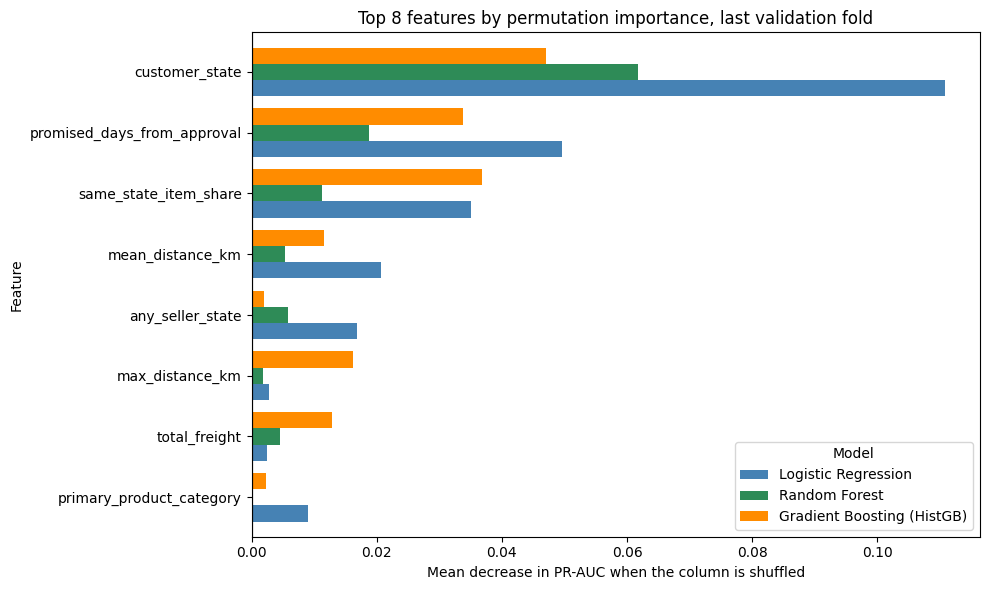

In [35]:
top8 = importance_compare.head(8).iloc[::-1]  # already ranked by largest importance in any model

ax = top8.plot.barh(figsize=(10, 6), width=0.8, color=["steelblue", "seagreen", "darkorange"])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Mean decrease in PR-AUC when the column is shuffled")
ax.set_ylabel("Feature")
ax.set_title("Top 8 features by permutation importance, last validation fold")
ax.legend(title="Model")
plt.tight_layout()
plt.show()

**Results and Interpretation**

All three models rely on the same four variables: `customer_state`, `promised_days_from_approval`, `same_state_item_share` and distance. Customer state is the most important variable for every model (PR-AUC drop of 0.111 for logistic regression, 0.062 for random forest and 0.047 for HistGB).

There are two differences. HistGB spreads the distance signal across both distance columns (`max_distance_km` 0.016, `mean_distance_km` 0.012) and also uses `total_freight` (0.013), which is largely priced on distance. Logistic regression gives more weight to seller state (0.017, against 0.006 and 0.002 for the tree models).

Product category, price, weight, purchase time and approval lag are close to zero for all three models. The tree models' importances are smaller overall because their PR-AUC on this fold is lower (0.31 and 0.30, against 0.36), so there is less to lose when a column is shuffled.

Because the three models lean on the same few geography and promise variables, it is not surprising that they miss many of the same late orders (4.3.4). Random forest results can shift slightly between machines (README section 7), so its values here may differ in the third decimal.